Modality: CT
Physical Pixel Spacing: [0.661468, 0.661468] mm
3D Volume Shape: (3, 128, 128) (Slices, Rows, Cols)
AI-Ready Range: 0.0 to 1.0
Voxel Depth (Z-spacing): 5.000000 mm


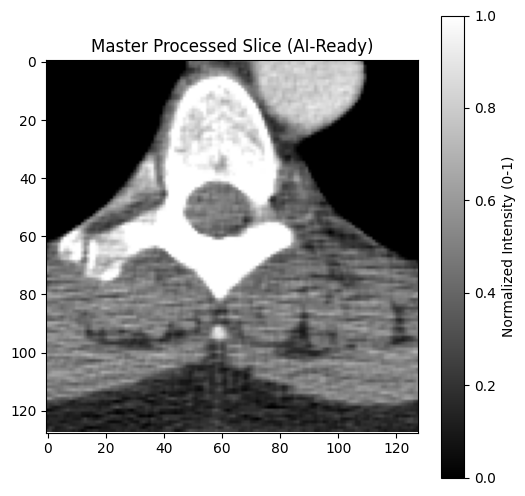

In [ ]:
# ==========================================
!pip install pydicom
# STEP 1: INSTALL & IMPORT LIBRARIES (Day 1)
# ==========================================
# Run this if pydicom isn't installed: !pip install pydicom
import pydicom
import numpy as np
import matplotlib.pyplot as plt
from pydicom.data import get_testdata_files

# ==========================================
# STEP 2: LOAD DATA & METADATA (Day 1)
# ==========================================
# Get a sample CT slice from the pydicom library
filename = get_testdata_files("CT_small.dcm")[0]
ds = pydicom.dcmread(filename)

# Extract raw pixel grid
image_array = ds.pixel_array

# ==========================================
# STEP 3: PHYSICS CALIBRATION (Day 2)
# ==========================================
# Convert raw values to Hounsfield Units (HU)
# Formula: HU = (Raw * Slope) + Intercept
hu_image = image_array * ds.RescaleSlope + ds.RescaleIntercept

# ==========================================
# STEP 4: WINDOWING & NORMALIZATION (Day 2)
# ==========================================
# We will focus on 'Soft Tissue' windowing (Center 40, Width 400)
# This means our range is -160 to +240
window_min, window_max = -160, 240
windowed_image = np.clip(hu_image, window_min, window_max)

# Normalize to 0.0 - 1.0 for the AI model
norm_image = (windowed_image - window_min) / (window_max - window_min)

# ==========================================
# STEP 5: 3D STACKING SIMULATION (Day 3)
# ==========================================
# In a real project, you'd load multiple .dcm files.
# Here, we stack our slice 3 times to create a 3D volume.
volume_3d = np.stack([hu_image, hu_image, hu_image], axis=0)

# ==========================================
# STEP 6: VISUALIZATION & VERIFICATION
# ==========================================
print(f"Modality: {ds.Modality}")
print(f"Physical Pixel Spacing: {ds.PixelSpacing} mm")
print(f"3D Volume Shape: {volume_3d.shape} (Slices, Rows, Cols)")
print(f"AI-Ready Range: {norm_image.min()} to {norm_image.max()}")
# Usually, we use Slice Thickness as the Z-dimension
z_spacing = ds.SliceThickness

print(f"Voxel Depth (Z-spacing): {z_spacing} mm")

# Display the final normalized slice
plt.figure(figsize=(6,6))
plt.imshow(norm_image, cmap='gray')
plt.title("Master Processed Slice (AI-Ready)")
plt.colorbar(label="Normalized Intensity (0-1)")
plt.show()

In [ ]:

import pydicom
import os
import numpy as np
import matplotlib.pyplot as plt
from pydicom.data import get_testdata_files

# Create a 'fake' folder and put 3 sample slices in it so we can practice
sample_files = get_testdata_files("CT_small.dcm") # This is actually one slice
# For learning, we will act as if we have multiple files
folder_path = "sample_ct_folder"
os.makedirs(folder_path, exist_ok=True)

# We save the sample file 3 times with different names to simulate a folder
for i in range(1, 4):
    ds_temp = pydicom.dcmread(sample_files[0])
    ds_temp.InstanceNumber = i  # We manually set the order 1, 2, 3
    ds_temp.save_as(os.path.join(folder_path, f"slice_{i}.dcm"))

print(f"✅ Folder created at: {folder_path} with 3 slices.")
# 1. Load all files
files_in_folder = os.listdir(folder_path)
slices = [pydicom.dcmread(os.path.join(folder_path, f)) for f in files_in_folder]

# 2. Sort by Instance Number (The 'Safety' step)
slices.sort(key=lambda x: int(x.InstanceNumber))

# 3. Stack into 3D
volume_3d = np.stack([s.pixel_array for s in slices])

# 4. Continuity Check
instance_numbers = [int(s.InstanceNumber) for s in slices]
print(f"Instance sequence: {instance_numbers}")
print(f"Final 3D Volume Shape: {volume_3d.shape}")


✅ Folder created at: sample_ct_folder with 3 slices.
Instance sequence: [1, 2, 3]
Final 3D Volume Shape: (3, 128, 128)
